# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Sandi Suryo Nugroho | 5054251020 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('insurance.csv')

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [6]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
cat_features_eda = ['sex', 'smoker', 'region']
for col in cat_features_eda:
    print(f'--- {col} ---')
    print(df[col].value_counts())
    print()

--- sex ---
sex
male      676
female    662
Name: count, dtype: int64

--- smoker ---
smoker
no     1064
yes     274
Name: count, dtype: int64

--- region ---
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64



## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


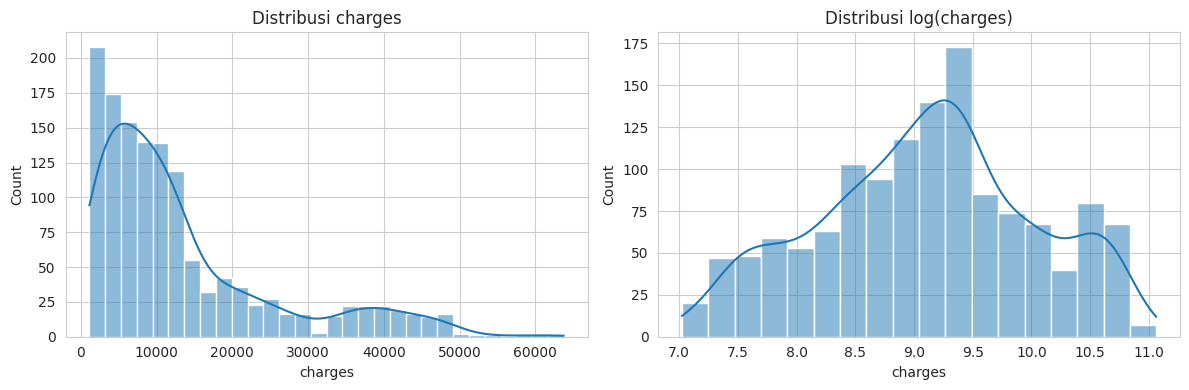

In [8]:
# Distribusi target (charges) dan log(charges)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['charges'], kde=True, ax=axes[0])
axes[0].set_title('Distribusi charges')
sns.histplot(np.log1p(df['charges']), kde=True, ax=axes[1])
axes[1].set_title('Distribusi log(charges)')
plt.tight_layout()
plt.show()

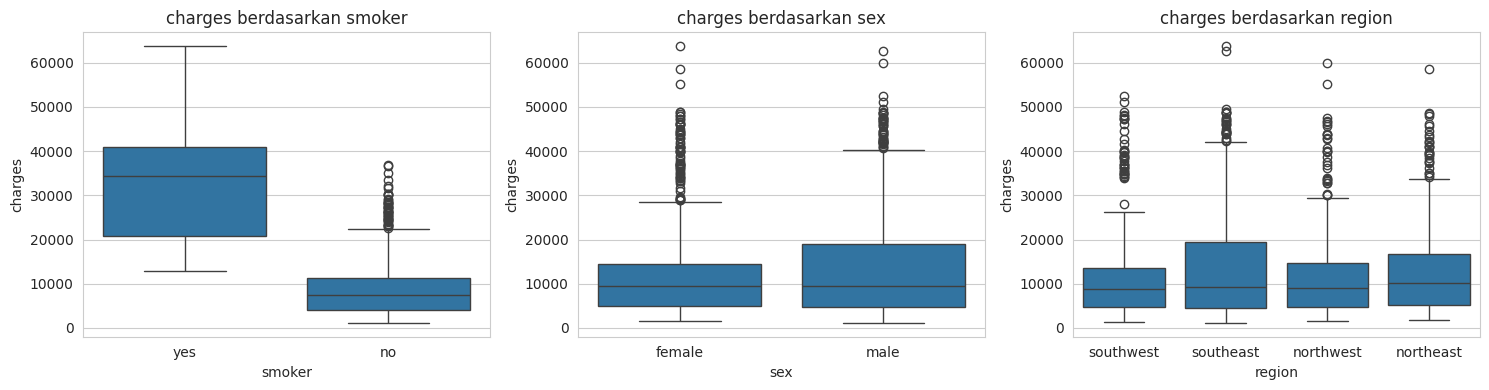

In [9]:
# Pengaruh fitur kategorikal terhadap charges
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['smoker', 'sex', 'region']):
    sns.boxplot(data=df, x=col, y='charges', ax=ax)
    ax.set_title(f'charges berdasarkan {col}')
plt.tight_layout()
plt.show()

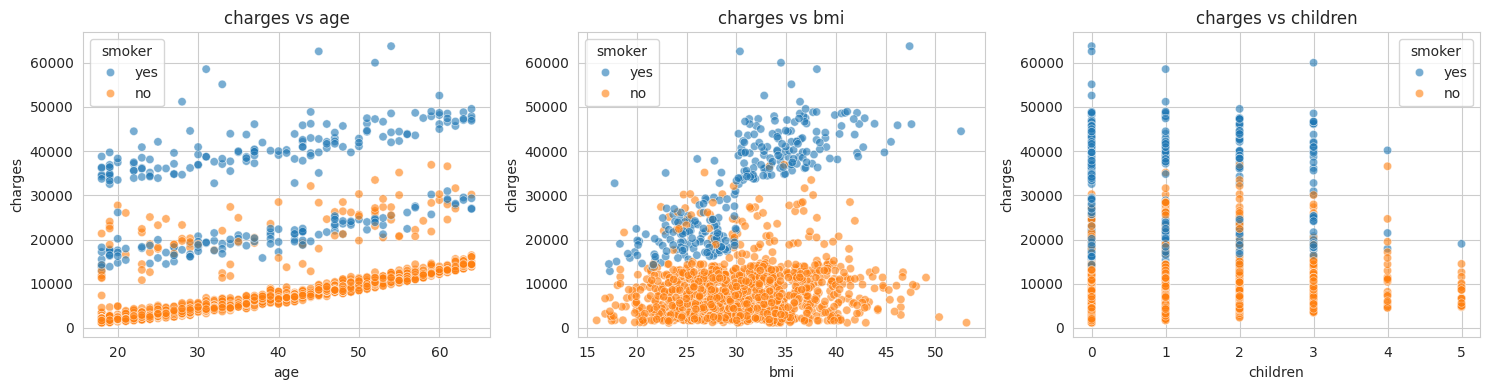

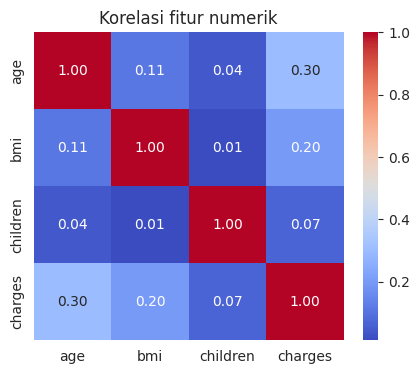

In [10]:
# Hubungan fitur numerik dengan charges (warna = smoker)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['age', 'bmi', 'children']):
    sns.scatterplot(data=df, x=col, y='charges', hue='smoker', alpha=0.6, ax=ax)
    ax.set_title(f'charges vs {col}')
plt.tight_layout()
plt.show()

# Korelasi fitur numerik
plt.figure(figsize=(5, 4))
sns.heatmap(df[['age', 'bmi', 'children', 'charges']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi fitur numerik')
plt.show()

**Temuan EDA:**
- Dataset 1338 baris, 6 fitur + target `charges`, tanpa missing value.
- `charges` miring ke kanan (skewness ≈ 1.5): sebagian besar biaya rendah, sebagian kecil sangat tinggi.
- `smoker` adalah faktor paling berpengaruh: rata-rata `charges` perokok ≈ 32.050 vs bukan perokok ≈ 8.434.
- `age` (korelasi 0.30) dan `bmi` (0.20) berpengaruh positif; `children` lemah (0.07). `sex` dan `region` hampir tidak berpengaruh.
- Scatter plot `bmi` menunjukkan hubungan tidak linear murni, sehingga model non-linear diperkirakan lebih unggul.

# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [11]:
X = df.drop(columns='charges')
y = df['charges']
print(X.shape, y.shape)

(1338, 6) (1338,)


In [12]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()
print('Numerik     :', numeric_features)
print('Kategorikal :', categorical_features)

Numerik     : ['age', 'bmi', 'children']
Kategorikal : ['sex', 'smoker', 'region']


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (1070, 6) | Test: (268, 6)


In [14]:
# Preprocessing dengan scaling (untuk Linear, Polynomial, Ridge, Lasso, SVR)
preprocess_scaled = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
])

# Preprocessing tanpa scaling (untuk Decision Tree): numerik dibiarkan apa adanya
preprocess_tree = ColumnTransformer([
    ('num', 'passthrough', numeric_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
])

# Helper: cross-validation R2 pada train set (untuk memilih parameter, test set tidak disentuh)
def cv_r2(model):
    return cross_val_score(model, X_train, y_train, cv=5, scoring='r2').mean()

# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [15]:
lin_reg = Pipeline([
    ('prep', preprocess_scaled),
    ('model', LinearRegression()),
])
lin_reg.fit(X_train, y_train)
print('CV R2 (train):', round(cv_r2(lin_reg), 4))

CV R2 (train): 0.7331


In [16]:
y_pred_lin = lin_reg.predict(X_test)

## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [17]:
# Eksperimen degree polynomial dengan 5-fold CV pada train set
for d in [1, 2, 3, 4]:
    m = Pipeline([
        ('prep', preprocess_scaled),
        ('poly', PolynomialFeatures(degree=d, include_bias=False)),
        ('model', LinearRegression()),
    ])
    print(f'degree={d} -> CV R2 = {cv_r2(m):.4f}')

# Degree terbaik berdasarkan hasil eksperimen di atas
best_degree = 2
poly_reg = Pipeline([
    ('prep', preprocess_scaled),
    ('poly', PolynomialFeatures(degree=best_degree, include_bias=False)),
    ('model', LinearRegression()),
])
poly_reg.fit(X_train, y_train)

degree=1 -> CV R2 = 0.7331


degree=2 -> CV R2 = 0.8268
degree=3 -> CV R2 = 0.8137


degree=4 -> CV R2 = 0.7128


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contai

In [18]:
y_pred_poly = poly_reg.predict(X_test)

## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [19]:
# Eksperimen nilai alpha dengan 5-fold CV pada train set
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
for a in alphas:
    m = Pipeline([('prep', preprocess_scaled), ('model', Ridge(alpha=a))])
    print(f'alpha={a:<8} -> CV R2 = {cv_r2(m):.4f}')

ridge_grid = GridSearchCV(
    Pipeline([('prep', preprocess_scaled), ('model', Ridge())]),
    param_grid={'model__alpha': alphas}, cv=5, scoring='r2'
)
ridge_grid.fit(X_train, y_train)
ridge_reg = ridge_grid.best_estimator_
print('Alpha terbaik Ridge:', ridge_grid.best_params_['model__alpha'])

alpha=0.001    -> CV R2 = 0.7331
alpha=0.01     -> CV R2 = 0.7331
alpha=0.1      -> CV R2 = 0.7331


alpha=1        -> CV R2 = 0.7332
alpha=10       -> CV R2 = 0.7308


alpha=100      -> CV R2 = 0.6228
alpha=1000     -> CV R2 = 0.2195


Alpha terbaik Ridge: 1


In [20]:
y_pred_ridge = ridge_reg.predict(X_test)

## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [21]:
# Eksperimen nilai alpha dengan 5-fold CV pada train set
for a in alphas:
    m = Pipeline([('prep', preprocess_scaled), ('model', Lasso(alpha=a, max_iter=20000))])
    print(f'alpha={a:<8} -> CV R2 = {cv_r2(m):.4f}')

lasso_grid = GridSearchCV(
    Pipeline([('prep', preprocess_scaled), ('model', Lasso(max_iter=20000))]),
    param_grid={'model__alpha': alphas}, cv=5, scoring='r2'
)
lasso_grid.fit(X_train, y_train)
lasso_reg = lasso_grid.best_estimator_
print('Alpha terbaik Lasso:', lasso_grid.best_params_['model__alpha'])

# Koefisien Lasso (nilai 0 berarti fitur dibuang)
feat_names = lasso_reg.named_steps['prep'].get_feature_names_out()
pd.Series(lasso_reg.named_steps['model'].coef_, index=feat_names).round(2)

alpha=0.001    -> CV R2 = 0.7331
alpha=0.01     -> CV R2 = 0.7331
alpha=0.1      -> CV R2 = 0.7331
alpha=1        -> CV R2 = 0.7331


alpha=10       -> CV R2 = 0.7333


alpha=100      -> CV R2 = 0.7342
alpha=1000     -> CV R2 = 0.6775


Alpha terbaik Lasso: 100


num__age                  3519.44
num__bmi                  1888.55
num__children              428.20
cat__sex_male                0.00
cat__smoker_yes          23030.88
cat__region_northwest        0.00
cat__region_southeast       -0.00
cat__region_southwest       -0.00
dtype: float64

In [22]:
y_pred_lasso = lasso_reg.predict(X_test)

## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [23]:
# Eksperimen max_depth dan min_samples_leaf dengan 5-fold CV pada train set
dt_grid = GridSearchCV(
    Pipeline([('prep', preprocess_tree), ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))]),
    param_grid={
        'model__max_depth': [2, 3, 4, 5, 6, 8, 10, None],
        'model__min_samples_leaf': [1, 5, 10, 20, 30],
    },
    cv=5, scoring='r2'
)
dt_grid.fit(X_train, y_train)
dt_reg = dt_grid.best_estimator_
print('Parameter terbaik DT:', dt_grid.best_params_)
print('CV R2 terbaik       :', round(dt_grid.best_score_, 4))

Parameter terbaik DT: {'model__max_depth': 5, 'model__min_samples_leaf': 30}
CV R2 terbaik       : 0.8405


In [24]:
y_pred_dt = dt_reg.predict(X_test)

## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


In [25]:
# Target charges berskala besar (puluhan ribu), sehingga C perlu besar agar SVR bisa fit.
svr_grid = GridSearchCV(
    Pipeline([('prep', preprocess_scaled), ('model', SVR())]),
    param_grid={
        'model__kernel': ['rbf'],
        'model__C': [1, 10, 100, 1000, 10000, 100000],
        'model__gamma': ['scale', 0.01, 0.1],
        'model__epsilon': [0.1, 10, 100],
    },
    cv=5, scoring='r2', n_jobs=-1
)
svr_grid.fit(X_train, y_train)
svr_reg = svr_grid.best_estimator_
print('Parameter terbaik SVR:', svr_grid.best_params_)
print('CV R2 terbaik        :', round(svr_grid.best_score_, 4))

# Pembanding: SVR dengan parameter default
svr_default = Pipeline([('prep', preprocess_scaled), ('model', SVR())]).fit(X_train, y_train)
print('R2 test SVR default  :', round(r2_score(y_test, svr_default.predict(X_test)), 4))

Parameter terbaik SVR: {'model__C': 100000, 'model__epsilon': 100, 'model__gamma': 0.1, 'model__kernel': 'rbf'}
CV R2 terbaik        : 0.8278
R2 test SVR default  : -0.0715


In [26]:
y_pred_svr = svr_reg.predict(X_test)

# 4. Evaluasi Model

In [27]:
predictions = {
    'Linear Regression': y_pred_lin,
    'Polynomial Regression': y_pred_poly,
    'Ridge Regression': y_pred_ridge,
    'Lasso Regression': y_pred_lasso,
    'Decision Tree': y_pred_dt,
    'SVR': y_pred_svr,
}

rows = []
for name, pred in predictions.items():
    mse = mean_squared_error(y_test, pred)
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2': r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index('Model').round(4)
results.sort_values('R2', ascending=False)

,MAE,MSE,RMSE,R2
Model,,,,
Polynomial Regression,2729.5001,2.071281e+07,4551.1324,0.8666
Decision Tree,2728.0160,2.127087e+07,4612.0353,0.8630
SVR,1739.2667,2.155493e+07,4642.7285,0.8612
Linear Regression,4181.1945,3.359692e+07,5796.2847,0.7836
Ridge Regression,4193.1954,3.364539e+07,5800.4649,0.7833
Lasso Regression,4248.4925,3.426606e+07,5853.7221,0.7793


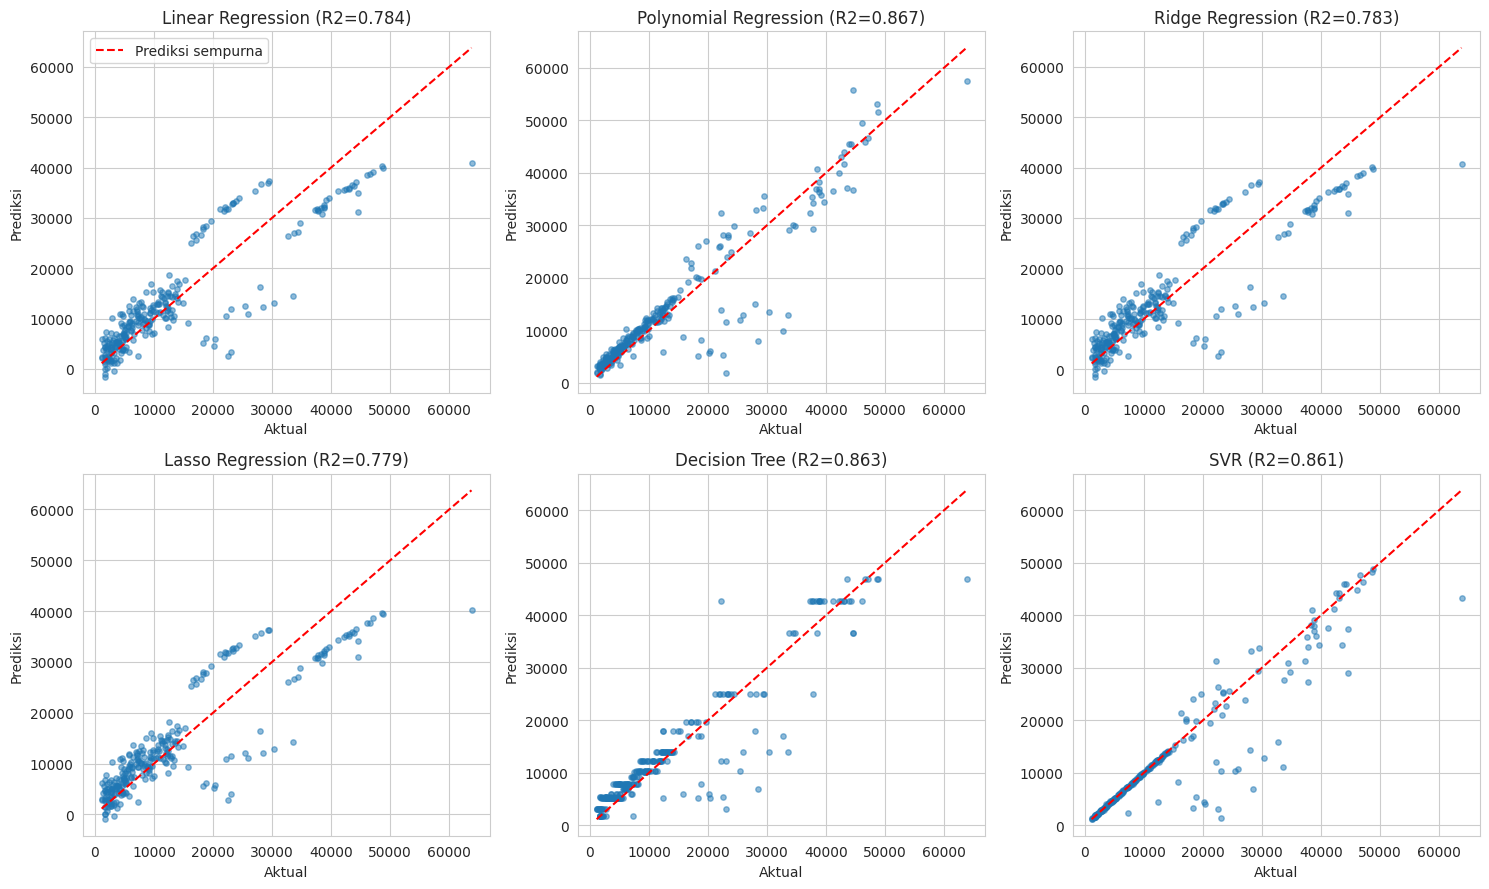

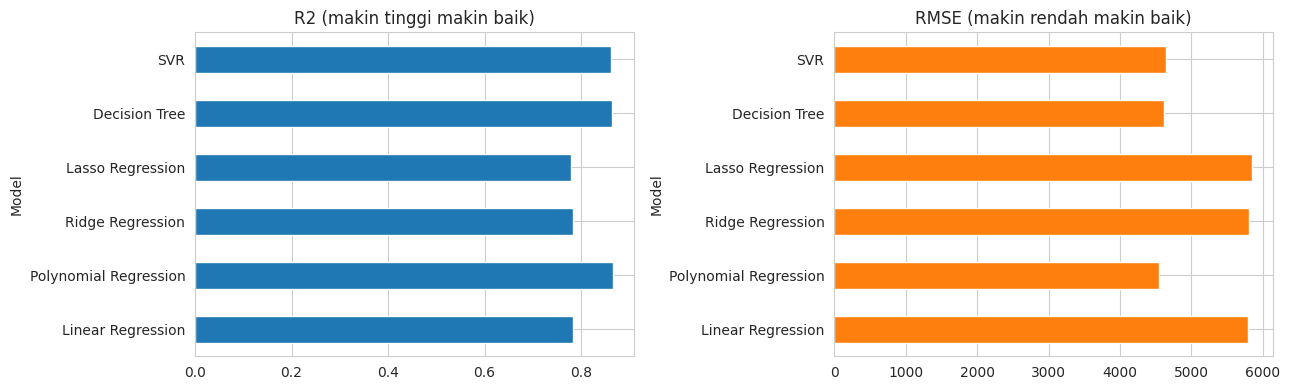

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
lims = [y_test.min(), y_test.max()]
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_test, pred, alpha=0.5, s=15)
    ax.plot(lims, lims, 'r--', label='Prediksi sempurna')
    ax.set_title(f"{name} (R2={r2_score(y_test, pred):.3f})")
    ax.set_xlabel('Aktual')
    ax.set_ylabel('Prediksi')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

# Perbandingan R2 dan RMSE
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results['R2'].plot.barh(ax=axes[0], title='R2 (makin tinggi makin baik)')
results['RMSE'].plot.barh(ax=axes[1], title='RMSE (makin rendah makin baik)', color='tab:orange')
plt.tight_layout()
plt.show()

# 5. Analisis

#### Bandingkan hasil Linear Regression, Polynomial Regression, Ridge, Lasso, Decision Tree Regressor, dan SVR berdasarkan metrik evaluasi. Jelaskan pengaruh preprocessing dan parameter yang digunakan terhadap hasil.


### Ringkasan hasil (test set)

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Polynomial Regression (degree=2) | 2729.50 | 4551.13 | 0.8666 |
| Decision Tree (max_depth=5, min_samples_leaf=30) | 2728.02 | 4612.04 | 0.8630 |
| SVR (RBF, C=100000, gamma=0.1, epsilon=100) | 1739.27 | 4642.73 | 0.8612 |
| Linear Regression | 4181.19 | 5796.28 | 0.7836 |
| Ridge Regression (alpha=1) | 4193.20 | 5800.46 | 0.7833 |
| Lasso Regression (alpha=100) | 4248.49 | 5853.72 | 0.7793 |

### Perbandingan model

- **Model linear (Linear, Ridge, Lasso)** punya performa hampir sama (R² ≈ 0.78). Ketiganya hanya bisa menangkap hubungan linear, padahal dari EDA pengaruh `smoker` bergantung pada `bmi` (interaksi). Itu sebabnya error-nya paling besar.

- **Polynomial Regression degree 2** naik ke R² ≈ 0.87 karena fitur kuadrat dan interaksi (misalnya `smoker × bmi`) menangkap pola non-linear. Degree 3 dan 4 justru lebih buruk di CV (0.814 dan 0.713) karena **overfitting**, jadi degree 2 dipilih.

- **Decision Tree** (R² ≈ 0.863) menangkap interaksi secara alami lewat percabangan. Tanpa pembatasan, pohon akan overfitting. `max_depth=5` dan `min_samples_leaf=30` menjaga pohon tetap sederhana.

- **SVR** (R² ≈ 0.861) punya MAE paling kecil, tetapi RMSE-nya sedikit lebih besar daripada Polynomial. Artinya SVR lebih akurat pada kasus umum, tetapi masih meleset besar di beberapa kasus biaya tinggi (RMSE sangat sensitif terhadap error besar).

### Pengaruh preprocessing

- **OneHotEncoder** wajib karena `sex`, `smoker`, `region` berupa teks/string. Dengan `drop='first'` kolom redundan dibuang, sehingga tidak ada multikolinearitas pada model linear.

- **StandardScaler** tidak mengubah hasil Linear Regression, tetapi penting untuk Ridge/Lasso (penalti bergantung pada skala koefisien) dan SVR (berbasis jarak). Decision Tree tidak butuh scaling karena split hanya bergantung pada urutan nilai.

### Pengaruh parameter

- **Ridge:** CV R² hampir datar untuk alpha ≤ 10, lalu turun tajam pada alpha ≥ 100 (underfitting). Dataset ini hanya punya sedikit fitur dan sedikit multikolinearitas, sehingga regularisasi hampir tidak membantu.

- **Lasso:** alpha terbaik = 100. Pada alpha ini koefisien `sex`, dan ketiga `region` menjadi 0, sehingga hanya `age`, `bmi`, `children`, `smoker` yang dipakai. Ini sesuai temuan EDA. Peningkatan CV R²-nya sangat kecil.

- **SVR:** dengan parameter default (C=1) R² test = **-0.07** (lebih buruk daripada menebak rata-rata), karena `charges` berskala puluhan ribu sedangkan `epsilon` dan `C` default dirancang untuk skala kecil. Setelah `C` dinaikkan besar, R² menjadi 0.86. Ini menunjukkan tuning parameter sangat menentukan untuk SVR.

- **Polynomial degree:** makin tinggi tidak selalu makin baik

# 6. Kesimpulan dan Saran

#### Berikan kesimpulan berdasarkan hasil eksperimen. Saran dapat berupa perubahan parameter, preprocessing, atau eksperimen lanjutan.


### Kesimpulan

1. Model terbaik pada test set adalah **Polynomial Regression degree 2** (R² = 0.8666, RMSE = 4551), disusul sangat dekat oleh Decision Tree dan SVR. Selisih ketiganya kecil, sehingga urutan ini bisa berubah jika `random_state` split diganti.
2. Model linear (Linear, Ridge, Lasso) jelas tertinggal (R² ≈ 0.78) karena data memiliki hubungan non-linear dan interaksi, terutama antara `smoker` dan `bmi`.
3. Regularisasi (Ridge/Lasso) hampir tidak meningkatkan performa karena masalah utamanya adalah **underfitting**, bukan overfitting. Lasso tetap berguna untuk seleksi fitur (membuang `sex` dan `region`).
4. Preprocessing yang tepat (OneHotEncoder, scaling untuk model yang sensitif skala) dan tuning parameter (terutama `C` pada SVR) sangat memengaruhi hasil.

### Saran

- Gunakan cross-validation untuk membandingkan model final, bukan satu kali split saja, agar perbedaan kecil antar model lebih dapat dipercaya.
- Tambahkan fitur interaksi eksplisit seperti `smoker × bmi` atau fitur `bmi > 30`, lalu coba lagi pada model linear/Ridge/Lasso.
